# Seismic Refraction (RF) — Line L1 (soccer field)

Workflow: load records → first breaks → traveltime curves → 2D tomography → velocity and material sections → joint Vp + Vs table.

In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from utils import seg2_io, refraction, plotting, interpretation
from utils.pick_refinement import select_refined_picks
from utils.tomography_selection import fit_model, predict
from utils.shot_stacking import restack_line

# --- Data ---
DATA_FOLDER = "L1/RF"
# The SEG-2 header of this shot says 42.5 m but the filename says 47.5 m
# (confirm against field notes).
SOURCE_X_OVERRIDES = {"2026-10-08_RF_47.5m.dat": 47.5}
# Re-stack the individual hits after removing trigger jitter (cross-correlation
# alignment to the median hit). The field stacks average misaligned hits.
RESTACK_ALIGNED = True
HIT_PATTERNS = {-5.0: "RF_-5m_shot", 12.5: "RF_12_shot", 27.5: "RF_27_shot",
                47.5: "RF_47_shot", 60.0: "RF_60m_shot"}
RESULT_FOLDER = Path("L1/RF_results")
RESULT_FOLDER.mkdir(parents=True, exist_ok=True)

# --- First breaks: reference picker + conservative AIC refinement ---
PICK_V_MIN, PICK_V_MAX = 150.0, 1500.0   # m/s, move-out bounds between receivers
PICK_NOISE_WINDOW = 0.010                # s, pre-arrival noise window
PICK_THRESHOLD = 3.0                     # trigger at threshold x noise RMS
# Manual corrections: {(shot_index, receiver_index): time_s or np.nan to discard}
PICK_OVERRIDES = {}

# --- 2D traveltime tomography (isotropic smoothing, homogeneous start) ---
PICK_ERROR = 0.0035     # s, assumed pick uncertainty
PARA_DEPTH = 8.0        # m, model depth
LAM = 1.0               # regularization strength
MAX_ITER = 12
Z_WEIGHT = 0.5          # vertical smoothness weight: 1 = isotropic, <1 favors horizontal layers

# --- Display ---
CONTOUR_INTERVAL = 500.0  # m/s

# --- Joint interpretation (Vs profile exported by L1_MASW_analysis) ---
MASW_VS_CSV = "L1/MASW_vs_profile.csv"
X_CENTER = 27.5                        # m, location of the 1D Vp(z) profile
Z_MIN_INTERP, Z_MAX_INTERP = 0.5, 10.0  # m
RHO = 1800.0                           # kg/m3, assumed soil density


## 1. Load shot gathers

In [3]:
gathers = seg2_io.read_line(DATA_FOLDER, source_x_overrides=SOURCE_X_OVERRIDES)
if RESTACK_ALIGNED:
    gathers = restack_line(gathers, DATA_FOLDER, HIT_PATTERNS)

Read 5 shot gathers from L1/RF:
  2026-10-08_RF_-5m.dat: source at -5.0 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz
  2026-10-08_RF_12.5m.dat: source at +12.5 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz
  2026-10-08_RF_27.5m.dat: source at +27.5 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz
  2026-10-08_RF_47.5m.dat: source at +47.5 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz
  2026-10-08_RF_60m.dat: source at +60.0 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz
  -5.0 m: 3 hits re-stacked, shifts [+0.62, -0.38, +0.00] ms
  +12.5 m: 3 hits re-stacked, shifts [+1.63, +0.00, -2.12] ms
  +27.5 m: 3 hits re-stacked, shifts [+0.50, +0.00, -0.75] ms
  +47.5 m: 3 hits re-stacked, shifts [+1.75, +0.00, -0.62] ms
  +60.0 m: hits unreadable (SEG2InvalidFileError); keeping field stack


## 2. First breaks

Reference picks are replaced by local AIC onsets only where three search windows agree within 2 ms and waveform contrast is clear (blue). Ambiguous traces keep the reference pick and are shown in orange for visual review. Manual `PICK_OVERRIDES` take precedence. No inversion residual is used to move or reject a pick.

In [4]:
reference_picks = refraction.pick_line(
    gathers, v_min=PICK_V_MIN, v_max=PICK_V_MAX,
    noise_window=PICK_NOISE_WINDOW, threshold=PICK_THRESHOLD,
)
picks, pick_diagnostics = select_refined_picks(gathers, reference_picks, overrides=PICK_OVERRIDES)
pick_diagnostics.to_csv(RESULT_FOLDER / "first_break_review.csv", index=False)
print(pick_diagnostics.selection_method.value_counts().to_string())
print(f"{pick_diagnostics.needs_review.sum()} unresolved picks (orange) need visual review.")

selection_method
unresolved reference    37
stable AIC candidate    23
37 unresolved picks (orange) need visual review.


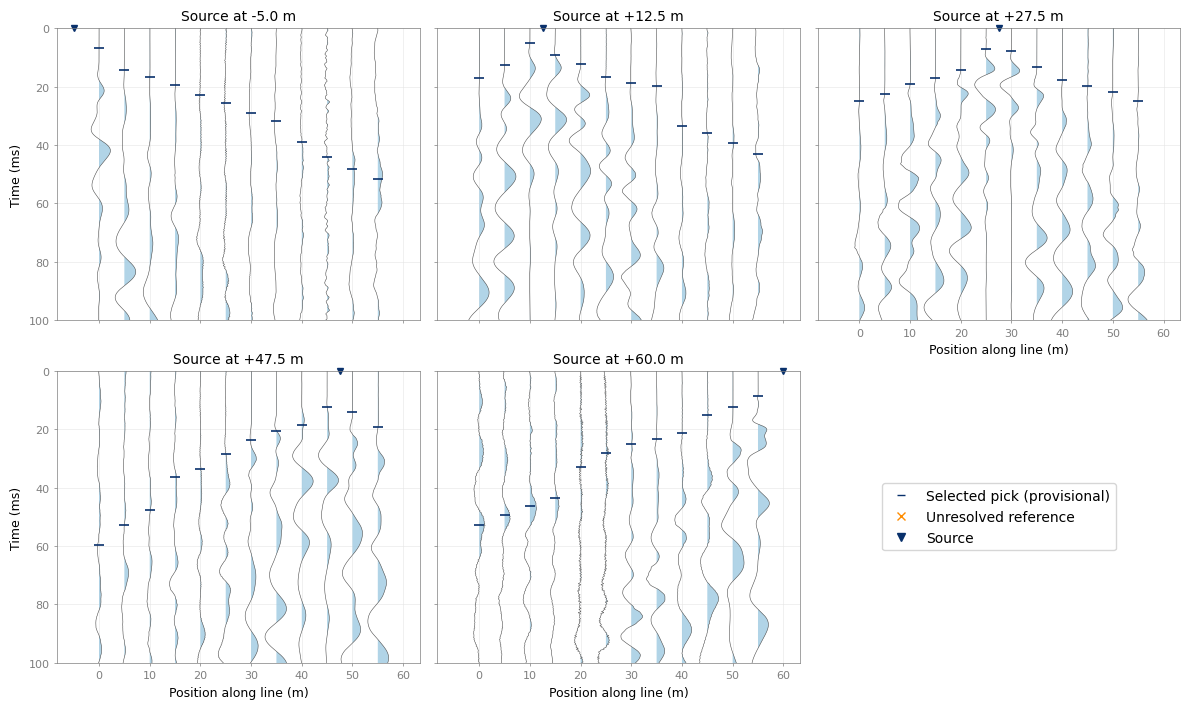

In [68]:
pick_overview = plotting.plot_all_gathers(
    gathers, t_max=0.10, picks_per_shot=picks,
    ncols=3, width=12.0, panel_aspect=0.9, fontsize=9,
    scale=0.45,                 # wiggle amplitude (fraction of trace spacing)
    fill_color="#9ecae1", fill_alpha=0.8,
    line_color="#4d4d4d", line_width=0.4,
    pick_color="#08306b", pick_size=7, source_size=5,
    axis_color="#7f7f7f",       # spines, tick marks, tick values
    label_color="k",            # axis labels and titles
    grid_color="#e5e5e5",       # None removes the grid
    legend_loc="center",        # position inside the spare slot
)
for i, (gather, ax) in enumerate(zip(gathers, pick_overview.axes)):
    rows = pick_diagnostics[pick_diagnostics.shot_index == i]
    uncertain = rows.needs_review.to_numpy() & np.isfinite(picks[i])
    #ax.plot(gather.receiver_x[uncertain], np.asarray(picks[i])[uncertain]*1000,
    #        'x', color='darkorange', ms=6, label='Unresolved reference')
from matplotlib.lines import Line2D
pick_overview.axes[-1].legend(handles=[
    Line2D([], [], color='#08306b', marker='_', ls='', label='Selected pick (provisional)'),
    Line2D([], [], color='darkorange', marker='x', ls='', label='Unresolved reference'),
    Line2D([], [], color='#08306b', marker='v', ls='', label='Source')], loc='center')
pick_overview.savefig(RESULT_FOLDER / 'first_break_overview.png', dpi=180, bbox_inches='tight')
plt.show()

## 3. Traveltime curves

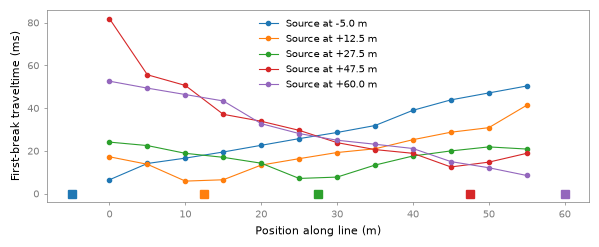

In [6]:
plotting.plot_traveltime_curves(
    gathers, picks,
    width=7.0, height=2.5, fontsize=8,
    line_width=0.8, marker="o", marker_size=3,
    source_marker="s", source_size=6,
    axis_color="#7f7f7f", label_color="k",
    grid_color="None",      # None removes the grid
    legend_loc="best",         # e.g. "upper center" or "center right"
    colors=None,               # list of colors to replace tab10
)
plt.show()

## 4. Apparent velocities

In [7]:
# With 5 m geophone spacing on soft ground the direct wave is only seen at
# the very nearest offsets, so the classic two-layer intercept method is not
# applicable; apparent velocities per shot/direction are reported instead.
refraction.apparent_velocities(gathers, picks)


,source_x_m,side,n_picks,v_apparent_m_s,intercept_ms
0,-5.0,right,12,1301.8,3.87
1,12.5,left,3,879.1,3.76
2,12.5,right,9,1346.8,5.82
3,27.5,left,6,1567.7,7.74
4,27.5,right,6,1871.7,8.90
5,47.5,left,10,767.0,3.87
6,60.0,left,12,1208.3,2.89


## 5. 2D traveltime tomography (pyGIMLi)

Smoothness-regularized inversion from a homogeneous starting velocity (median apparent velocity), depth 8 m and λ = 1. `Z_WEIGHT = 0.5` halves the vertical smoothness weight so lateral continuity is mildly favored (1 = isotropic). In a 3-fold held-out check this costs little: RMS 3.41 ms (isotropic) vs 3.44 ms (0.5). It is a preference, not evidence that the subsurface is layered. All waveform-selected picks are used; none are rejected by residual.

In [8]:
data_tt = refraction.build_traveltime_data(gathers, picks, pick_error=PICK_ERROR)
refraction.export_refrapy_picks(data_tt, RESULT_FOLDER / "L1_waveform_refined_picks.sgt")
mesh = refraction.create_mesh(data_tt, para_dx=0.5, para_depth=PARA_DEPTH,
                              max_cell_size=2.0, para_boundary=0.5)
manager = fit_model(data_tt, mesh, LAM, max_iter=MAX_ITER, z_weight=Z_WEIGHT)

positions = np.array([[p.x(), p.y()] for p in data_tt.sensorPositions()])
fit_table = pd.DataFrame(dict(
    source_x_m=positions[np.asarray(data_tt["s"], dtype=int), 0],
    receiver_x_m=positions[np.asarray(data_tt["g"], dtype=int), 0],
    observed_ms=np.asarray(data_tt["t"]) * 1000,
    predicted_ms=predict(manager, data_tt) * 1000,
))
fit_table["residual_ms"] = fit_table.observed_ms - fit_table.predicted_ms
fit_table.to_csv(RESULT_FOLDER / "prediction_diagnostics.csv", index=False)
manager.paraDomain.save(str(RESULT_FOLDER / "selected_mesh.bms"))
np.save(RESULT_FOLDER / "selected_velocity.npy", np.asarray(manager.velocity))
velocity = np.asarray(manager.velocity)
print(f"{data_tt.size()} picks, RMS = {np.sqrt(np.mean(fit_table.residual_ms**2)):.2f} ms, "
      f"Vp = {velocity.min():.0f}-{velocity.max():.0f} m/s")

25/10/26 - 02:24:22 - pyGIMLi - INFO - Found 1 regions.


25/10/26 - 02:24:22 - pyGIMLi - INFO - Found 1 regions.


25/10/26 - 02:24:22 - pyGIMLi - INFO - Creating forward mesh from region infos.


25/10/26 - 02:24:22 - pyGIMLi - INFO - Creating refined mesh (secnodes: 2) to solve forward task.


25/10/26 - 02:24:22 - pyGIMLi - INFO - Create gradient starting model. 905.6732740943266: 905.6732740943266


Traveltime data: 17 sensors, 60 picks
Mesh: 593 cells, 343 nodes (paraDX=0.5, depth=8.0 m, quality=33.5)


25/10/26 - 02:24:23 - pyGIMLi - INFO - Creating refined mesh (secnodes: 2) to solve forward task.


60 picks, RMS = 3.96 ms, Vp = 102-2379 m/s


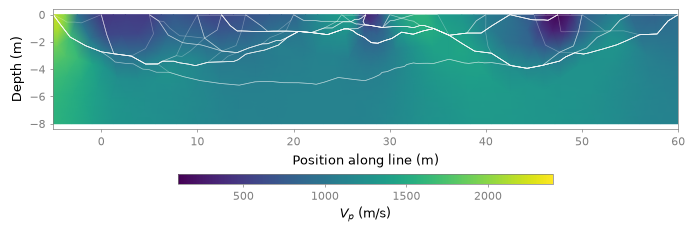

In [9]:
plotting.plot_tomogram(
    manager, width=7.0, height=2.2, fontsize=8, label_size=9, tick_size=8,
    cmap="viridis", v_exag=0.1, cbar_label="$V_{p}$ (m/s)", cbar_thickness=0.1,
    rays=True, smooth=True, xlim=(-5, 60)
)
plt.savefig(RESULT_FOLDER / "tomogram.png", dpi=180, bbox_inches="tight")
plt.show()

### 5.1 Observed vs predicted traveltimes

Circles are picks, lines are model predictions per shot, squares are sources.

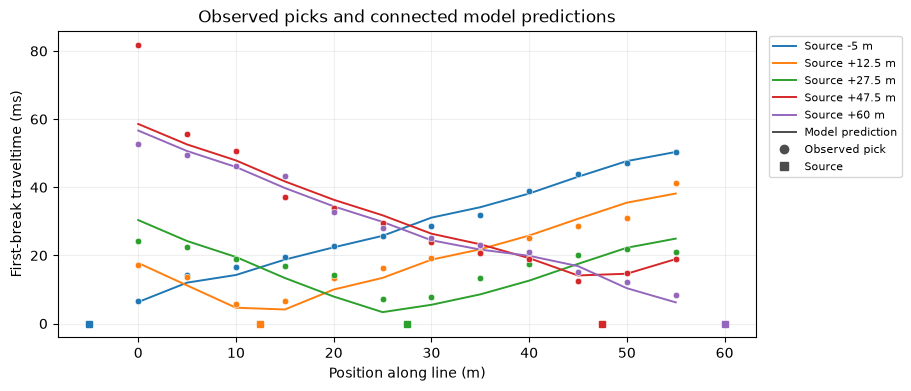

In [10]:
fit_ax = plotting.plot_traveltime_fit(manager, data_tt, width=9, height=3.8)
fit_ax.figure.savefig(RESULT_FOLDER / "observed_vs_predicted.png", dpi=180, bbox_inches="tight")
plt.show()

### 5.3 Indicative material classes

Light sand <500 m/s (loose / low-velocity soil), tan 500–1000 (soil / fill), dark brown 1000–1500 (dense or wetter soil), gray ≥1500 (saturated soil or weathered rock). Vp-based hypotheses only, not confirmed lithology or saturation.

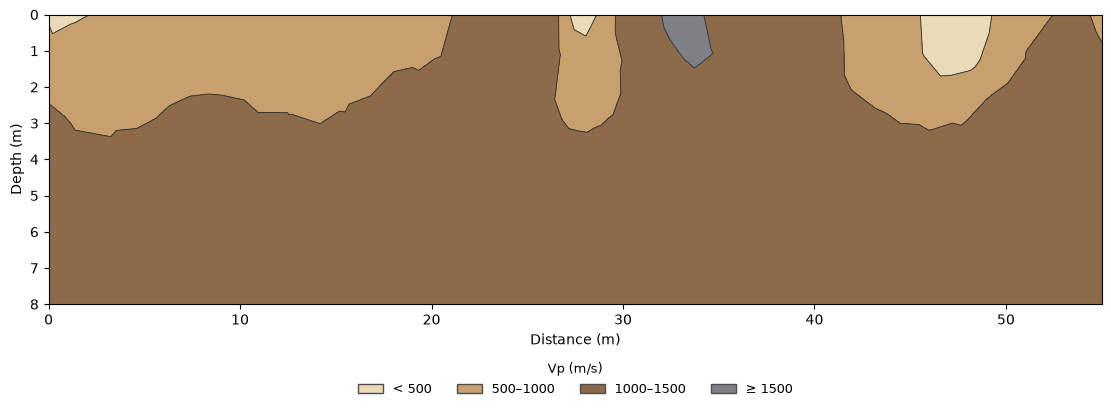

In [12]:
material_ax = plotting.plot_material_classes(manager, width=11, height=4, xlim=(0, 55))
material_ax.figure.savefig(RESULT_FOLDER / "indicative_material_classes.png", dpi=180, bbox_inches="tight")
plt.show()

## 6. Joint interpretation ($V_p$ + $V_s$)

In [13]:
vp_profile = interpretation.vp_profile_from_tomogram(
    manager, x_center=X_CENTER, z_min=Z_MIN_INTERP,
    z_max=min(Z_MAX_INTERP, -manager.paraDomain.yMin() - 0.001),
)
properties = interpretation.elastic_properties(vp_profile, pd.read_csv(MASW_VS_CSV), rho=RHO)
layers = interpretation.classify_materials(properties)
layers.drop(columns="color")

,top_m,bottom_m,vp_mean_m_s,vs_mean_m_s,poisson_mean,material
0,4.15,8.0,1111.0,451.0,0.4,Very dense soil / gravelly subbase


## 7. Material interpretation by Vp and Vs ranges

The first table shows typical ranges (Reynolds 2011; NEHRP / Eurocode 8 for Vs). The second applies them to the 1D profiles (mean Vp over 0–55 m, MASW Vs). Ranges overlap in nature, so each interpretation is a hypothesis. Above 4 m only Vp is available, and Vp alone cannot separate moist clay from compact gravel or confirm saturation. The figure shows the resulting material log; the thick outline marks the interval also constrained by Vs.

typical material
property range                                                          
Vp       < 500               dry loose soil, topsoil or uncompacted fill
         500–1000        unsaturated soil or compacted fill (sand, silt)
         1000–1500           dense or moist soil, clay or compact gravel
         ≥ 1500     saturated soil (below water table) or weathered rock
Vs       < 180                                       soft soil (NEHRP E)
         180–360                                    stiff soil (NEHRP D)
         360–760                  very dense soil or soft rock (NEHRP C)
         ≥ 760                                            rock (NEHRP B)
Vp/Vs    < 2                                    consolidated / rock-like
         2–3                                    typical unsaturated soil
         3–4                               soft or partly saturated soil
         ≥ 4                                            likely saturated

,top_m,bottom_m,vp_mean_m_s,vs_mean_m_s,vp_vs,vp_range,vs_range,material,class,interpretation
0,0.0,1.9,835.0,NaN,NaN,500–1000,no data,Unsaturated soil / fill,1,"Vp: unsaturated soil or compacted fill (sand, silt)"
1,1.9,4.1,1165.0,NaN,NaN,1000–1500,no data,Dense or moist soil,2,"Vp: dense or moist soil, clay or compact gravel"
2,4.1,8.0,1270.0,452.0,2.81,1000–1500,360–760,Dense or moist soil (Vs: very dense),2,"Vp: dense or moist soil, clay or compact gravel; Vs: very dense soil or soft rock (NEHRP C); Vp/Vs 2.8: typical unsaturated soil"


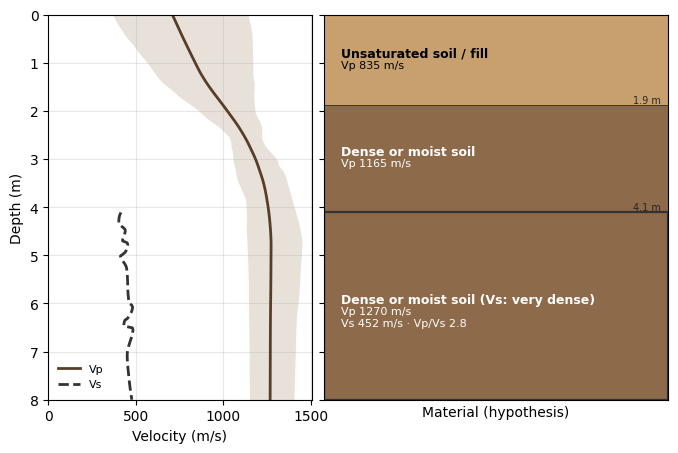

In [ ]:
vp_average = interpretation.average_vp_profile(
    manager, x_min=0.0, x_max=55.0, z_min=0.0,
    z_max=-manager.paraDomain.yMin() - 0.001, n_depths=80,
)
vs_masw = pd.read_csv(MASW_VS_CSV)
material_layers = interpretation.interpret_vp_vs(vp_average, vs_masw)
material_layers.to_csv(RESULT_FOLDER / "material_interpretation_1d.csv", index=False)
with pd.option_context("display.max_colwidth", None):
    display(interpretation.material_reference_table().set_index(["property", "range"]))
    display(material_layers.round({"top_m": 1, "bottom_m": 1, "vp_mean_m_s": 0,
                                   "vs_mean_m_s": 0, "vp_vs": 2}))

material_fig = plotting.plot_material_log(vp_average, vs_masw, material_layers)
material_fig.savefig(RESULT_FOLDER / "material_log_1d.png", dpi=180, bbox_inches="tight")
plt.show()